In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.utils.class_weight import compute_class_weight

In [2]:
# PATHS

ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Dataset")

TRAIN_DIR = ROOT_DIR / "Training"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Testing"


# CLASSES

CLASSES = [
    "Distraction",
    "Drinking",
    "Normal",
    "Phone",
    "Sleeping"
]

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASSES)
}


# TRAINING SETTINGS

SEED = 42

BATCH_SIZE = 16
NUM_WORKERS = 0

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# REPRODUCIBILITY

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

Device : cuda
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU


In [5]:
from pathlib import Path

ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Dataset")

TRAIN_DIR = ROOT_DIR / "Train"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Test"

print("Train exists     :", TRAIN_DIR.exists())
print("Validation exists:", VAL_DIR.exists())
print("Test exists      :", TEST_DIR.exists())

Train exists     : True
Validation exists: True
Test exists      : True


In [6]:
def build_dataframe(split_path):

    data = []

    person_folders = sorted([
        p for p in split_path.iterdir()
        if p.is_dir()
    ])

    for person_folder in person_folders:

        person_name = person_folder.name

        for class_name in CLASSES:

            class_folder = person_folder / class_name

            if not class_folder.exists():
                continue

            for image_path in class_folder.iterdir():

                if image_path.suffix.lower() in IMAGE_EXTENSIONS:

                    data.append({
                        "path": str(image_path),
                        "person": person_name,
                        "class": class_name,
                        "label": CLASS_TO_IDX[class_name]
                    })

    return pd.DataFrame(data)


train_df = build_dataframe(TRAIN_DIR)
val_df   = build_dataframe(VAL_DIR)
test_df  = build_dataframe(TEST_DIR)


print("Training Images  :", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images   :", len(test_df))

print("\nTraining Persons:")
print(sorted(train_df["person"].unique()))

print("\nValidation Persons:")
print(sorted(val_df["person"].unique()))

print("\nTesting Persons:")
print(sorted(test_df["person"].unique()))

Training Images  : 25779
Validation Images: 3548
Testing Images   : 3565

Training Persons:
['Person1', 'Person2', 'Person3', 'Person4', 'Person5', 'Person6', 'Person7']

Validation Persons:
['Person8']

Testing Persons:
['Person9']


In [7]:
print("TRAINING CLASS COUNTS")
print(train_df["class"].value_counts().sort_index())

print("\nVALIDATION CLASS COUNTS")
print(val_df["class"].value_counts().sort_index())

print("\nTESTING CLASS COUNTS")
print(test_df["class"].value_counts().sort_index())

TRAINING CLASS COUNTS
class
Distraction    4836
Drinking       5736
Normal         4895
Phone          5333
Sleeping       4979
Name: count, dtype: int64

VALIDATION CLASS COUNTS
class
Distraction    712
Drinking       636
Normal         633
Phone          901
Sleeping       666
Name: count, dtype: int64

TESTING CLASS COUNTS
class
Distraction    696
Drinking       642
Normal         709
Phone          819
Sleeping       699
Name: count, dtype: int64


In [8]:
# IMAGE TRANSFORMS

train_transform = transforms.Compose([

    # Geometric Augmentation 
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=8),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),   # slight seat shift
        scale=(0.95, 1.05)
    ),

    #Lighting Augmentation
    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.15,
        hue=0.03
    ),

    # Slight blur to reduce identity memorization
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3)
    ], p=0.20),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation & Test
# No augmentation — only normalization

test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(row["path"]).convert("RGB")

        image = self.transform(image)

        label = row["label"]

        return image, label


train_dataset = DriverDataset(train_df, train_transform)
val_dataset   = DriverDataset(val_df, test_transform)
test_dataset  = DriverDataset(test_df, test_transform)

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# Class Weights (for imbalance)


weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"]
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("Class Weights")
for c, w in zip(CLASSES, weights):
    print(f"{c:15s}: {w:.3f}")

print("\nTrain Batches :", len(train_loader))
print("Val Batches   :", len(val_loader))
print("Test Batches  :", len(test_loader))

Class Weights
Distraction    : 1.066
Drinking       : 0.899
Normal         : 1.053
Phone          : 0.967
Sleeping       : 1.036

Train Batches : 1612
Val Batches   : 222
Test Batches  : 223


In [11]:
# CUSTOM CNN

class CustomCNN(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),


            # Block 2
            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),


            # Block 3
            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),


            # Block 4
            nn.Conv2d(
                128, 256,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),


            # Block 5
            nn.Conv2d(
                256, 512,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            # Global pooling
            nn.AdaptiveAvgPool2d((1, 1))
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            # First fully connected layer
            nn.Dropout(0.60),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(inplace=True),

            # Output layer
            nn.Dropout(0.40),

            nn.Linear(
                256,
                num_classes
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# CREATE MODEL

model = CustomCNN(
    len(CLASSES)
).to(DEVICE)


# COUNT TRAINABLE PARAMETERS

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(model)

print(
    f"\nTrainable Parameters: {total_params:,}"
)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1

In [12]:
# VERIFY SHAPES


images, labels = next(iter(train_loader))

print("Input Shape :", images.shape)

images = images.to(DEVICE)

outputs = model(images)

print("Output Shape:", outputs.shape)

Input Shape : torch.Size([16, 3, 480, 854])
Output Shape: torch.Size([16, 5])


In [13]:
# TRAINING CONFIGURATION

LEARNING_RATE = 1e-4
EPOCHS = 25


# Loss Function

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)


# Optimizer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


# Learning Rate Scheduler

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    threshold=1e-3,
    min_lr=1e-6
)


# Mixed Precision

scaler = torch.amp.GradScaler("cuda")


# Early Stopping

EARLY_STOPPING_PATIENCE = 7


print("Training Configuration")

print(f"Learning Rate : {LEARNING_RATE}")
print(f"Epochs        : {EPOCHS}")
print(f"Patience      : {EARLY_STOPPING_PATIENCE}")

Training Configuration
Learning Rate : 0.0001
Epochs        : 25
Patience      : 7


In [14]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}

best_f1 = 0
trigger = 0

best_model = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print("-" * 50)

    model.train()

    train_loss = 0
    train_true = []
    train_pred = []

    for images, labels in tqdm(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

        preds = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(preds.cpu().numpy())

    train_loss /= len(train_loader)

    train_acc = accuracy_score(
        train_true,
        train_pred
    )

    train_f1 = f1_score(
        train_true,
        train_pred,
        average="macro"
    )


    # VALIDATION

    model.eval()

    val_loss = 0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in tqdm(val_loader):

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_loss /= len(val_loader)

    val_acc = accuracy_score(
        val_true,
        val_pred
    )

    val_f1 = f1_score(
        val_true,
        val_pred,
        average="macro"
    )


    # LEARNING RATE SCHEDULER

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]


    # SAVE HISTORY

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)


    # SAVE BEST MODEL

    if val_f1 > best_f1:

        best_f1 = val_f1
        trigger = 0

        best_model = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model,
            "best_personwise_custom_cnn.pth"
        )

        status = "Best Model Saved"

    else:

        trigger += 1
        status = (
            f"EarlyStop "
            f"{trigger}/{EARLY_STOPPING_PATIENCE}"
        )


    # PRINT RESULTS

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Acc : {train_acc:.4f} | "
        f"F1 : {train_f1:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f} | "
        f"Acc : {val_acc:.4f} | "
        f"F1 : {val_f1:.4f}"
    )

    print(
        f"Learning Rate : {current_lr:.2e}"
    )

    print(status)


    # EARLY STOPPING

    if trigger >= EARLY_STOPPING_PATIENCE:

        print("\nEarly Stopping Triggered")
        break


print("\nTraining Completed")
print(f"Best Validation F1: {best_f1:.4f}")


Epoch [1/25]
--------------------------------------------------


100%|██████████| 222/222 [01:08<00:00,  3.24it/s]


Train Loss : 1.5682 | Acc : 0.2675 | F1 : 0.2644
Val Loss   : 1.6053 | Acc : 0.2210 | F1 : 0.1143
Learning Rate : 1.00e-04
Best Model Saved

Epoch [2/25]
--------------------------------------------------


100%|██████████| 222/222 [00:35<00:00,  6.28it/s]


Train Loss : 1.4997 | Acc : 0.3283 | F1 : 0.3183
Val Loss   : 1.5570 | Acc : 0.2748 | F1 : 0.2100
Learning Rate : 1.00e-04
Best Model Saved

Epoch [3/25]
--------------------------------------------------


100%|██████████| 222/222 [00:44<00:00,  4.97it/s]


... (41 outputs left out)

100%|██████████| 222/222 [00:34<00:00,  6.43it/s]


Train Loss : 0.6218 | Acc : 0.8337 | F1 : 0.8335
Val Loss   : 1.5113 | Acc : 0.5054 | F1 : 0.4612
Learning Rate : 2.50e-05
EarlyStop 2/7

Epoch [25/25]
--------------------------------------------------


100%|██████████| 222/222 [00:34<00:00,  6.42it/s]

Train Loss : 0.6142 | Acc : 0.8370 | F1 : 0.8370
Val Loss   : 1.6122 | Acc : 0.4188 | F1 : 0.4090
Learning Rate : 1.25e-05
EarlyStop 3/7

Training Completed
Best Validation F1: 0.5983


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# LOAD BEST MODEL


model.load_state_dict(
    torch.load(
        "best_personwise_custom_cnn.pth",
        map_location=DEVICE,
        weights_only=True
    )
)
model.eval()

test_predictions = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)

        preds = outputs.argmax(dim=1).cpu().numpy()

        test_predictions.extend(preds)
        test_labels.extend(labels.numpy())

print("Best model loaded successfully.")

Best model loaded successfully.


In [18]:
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)


print("FINAL TEST RESULTS")

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"Macro F1  : {test_f1:.4f}")


print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)


cm = confusion_matrix(
    test_labels,
    test_predictions
)

FINAL TEST RESULTS
Accuracy  : 0.5599
Precision : 0.5358
Recall    : 0.5616
Macro F1  : 0.5030

CLASSIFICATION REPORT

              precision    recall  f1-score   support

 Distraction     0.4539    0.9899    0.6224       696
    Drinking     0.7941    0.7087    0.7490       642
      Normal     0.2800    0.0099    0.0191       709
       Phone     0.6662    0.6386    0.6521       819
    Sleeping     0.4849    0.4607    0.4725       699

    accuracy                         0.5599      3565
   macro avg     0.5358    0.5616    0.5030      3565
weighted avg     0.5354    0.5599    0.5026      3565



In [19]:
#Create Results Folder

from pathlib import Path

RESULTS_DIR = Path("Training_Results")
RESULTS_DIR.mkdir(exist_ok=True)

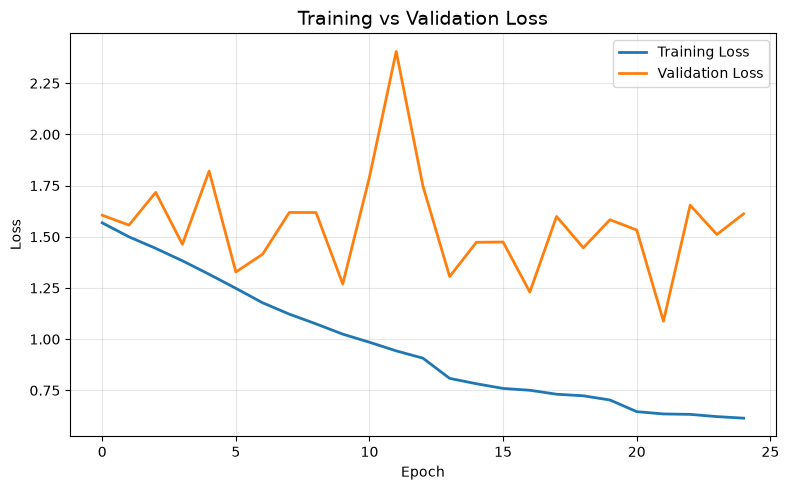

In [20]:
#Loss Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_loss"], linewidth=2, label="Training Loss")
plt.plot(history["val_loss"], linewidth=2, label="Validation Loss")

plt.title("Training vs Validation Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=300)
plt.show()

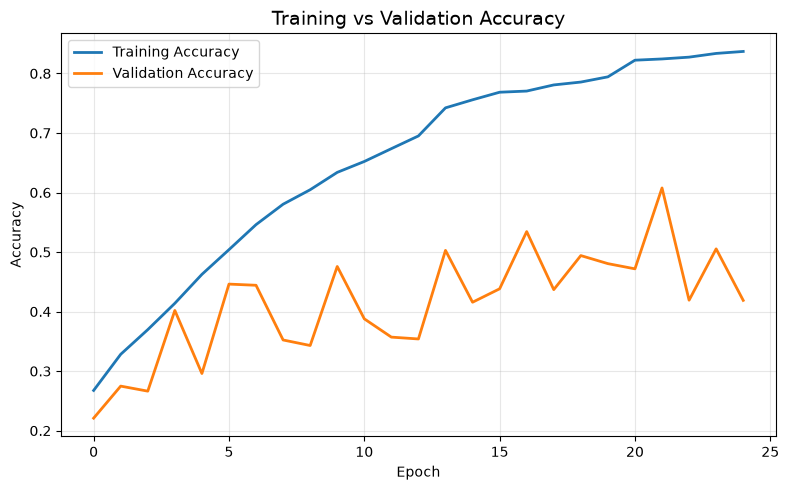

In [21]:
#Accuracy Curve

plt.figure(figsize=(8,5))

plt.plot(history["train_acc"], linewidth=2, label="Training Accuracy")
plt.plot(history["val_acc"], linewidth=2, label="Validation Accuracy")

plt.title("Training vs Validation Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_curve.png", dpi=300)
plt.show()

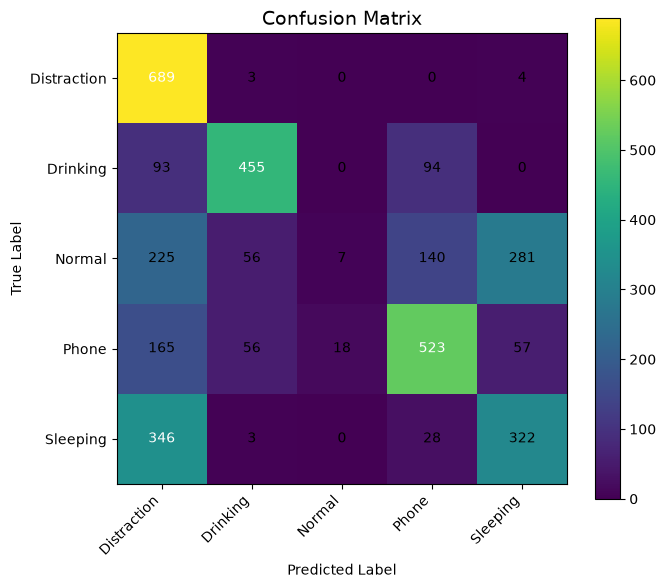

In [22]:
# Confusion Matrix

fig, ax = plt.subplots(figsize=(7,6))

im = ax.imshow(cm, interpolation="nearest")

ax.set_title("Confusion Matrix", fontsize=14)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))

ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticklabels(CLASSES)

# Write values inside cells
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.colorbar(im)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

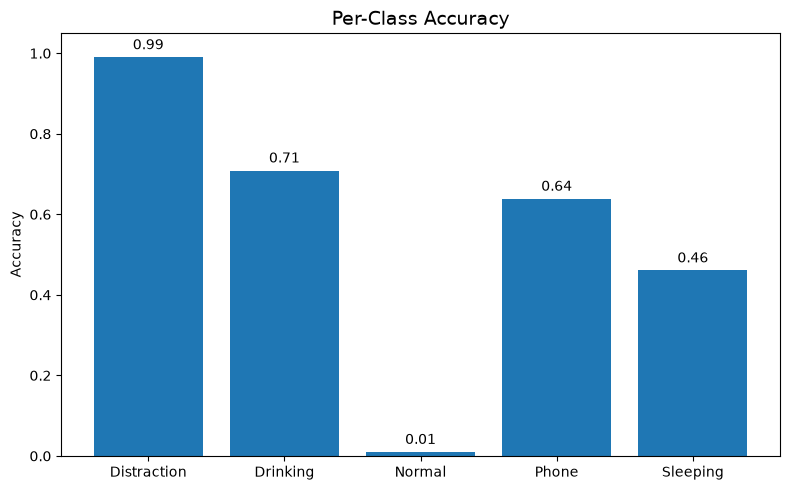

In [23]:
# Per-Class Accuracy
class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8,5))

plt.bar(CLASSES, class_accuracy)

plt.ylim(0,1.05)

plt.title("Per-Class Accuracy", fontsize=14)
plt.ylabel("Accuracy")

for i, value in enumerate(class_accuracy):

    plt.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(RESULTS_DIR / "per_class_accuracy.png", dpi=300)
plt.show()

In [24]:
#Train summary

summary = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "Macro F1"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(summary)

summary.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)

,Metric,Value
0,Test Accuracy,0.559888
1,Precision,0.535827
2,Recall,0.561556
3,Macro F1,0.503011


Selected image:
C:\Btech\SEM5\cuda\DL\Dataset\Test\Person9\Phone\Sriram_PhoneUsage_Dashboard_000631.jpg
Image size: (854, 480)


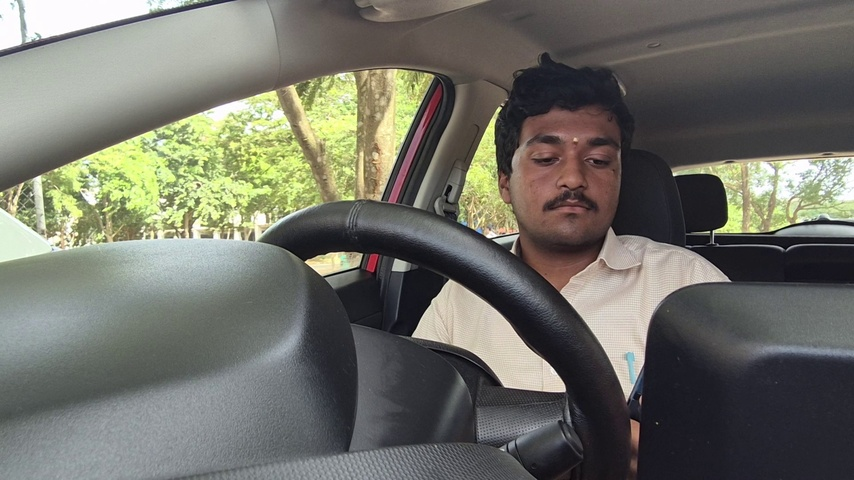

In [29]:
# FIND A VISUALLY INFORMATIVE TEST IMAGE

from PIL import Image
import numpy as np

best_path = None
best_score = -1

# Check test images and find one with good brightness + spatial variation

for _, row in test_df.iterrows():

    try:
        img = Image.open(row["path"]).convert("RGB")
        arr = np.asarray(img).astype(np.float32) / 255.0

        mean_brightness = arr.mean()
        spatial_variation = arr.std()

        # Avoid very dark / nearly uniform images
        score = mean_brightness * spatial_variation

        if score > best_score:
            best_score = score
            best_path = row["path"]

    except:
        continue


print("Selected image:")
print(best_path)

selected_image = Image.open(best_path).convert("RGB")

print("Image size:", selected_image.size)

display(selected_image)

Image: C:\Btech\SEM5\cuda\DL\Dataset\Test\Person9\Phone\Sriram_PhoneUsage_Dashboard_000631.jpg
True Class: Phone
Convolutional layers: 5
Predicted Class: Distraction


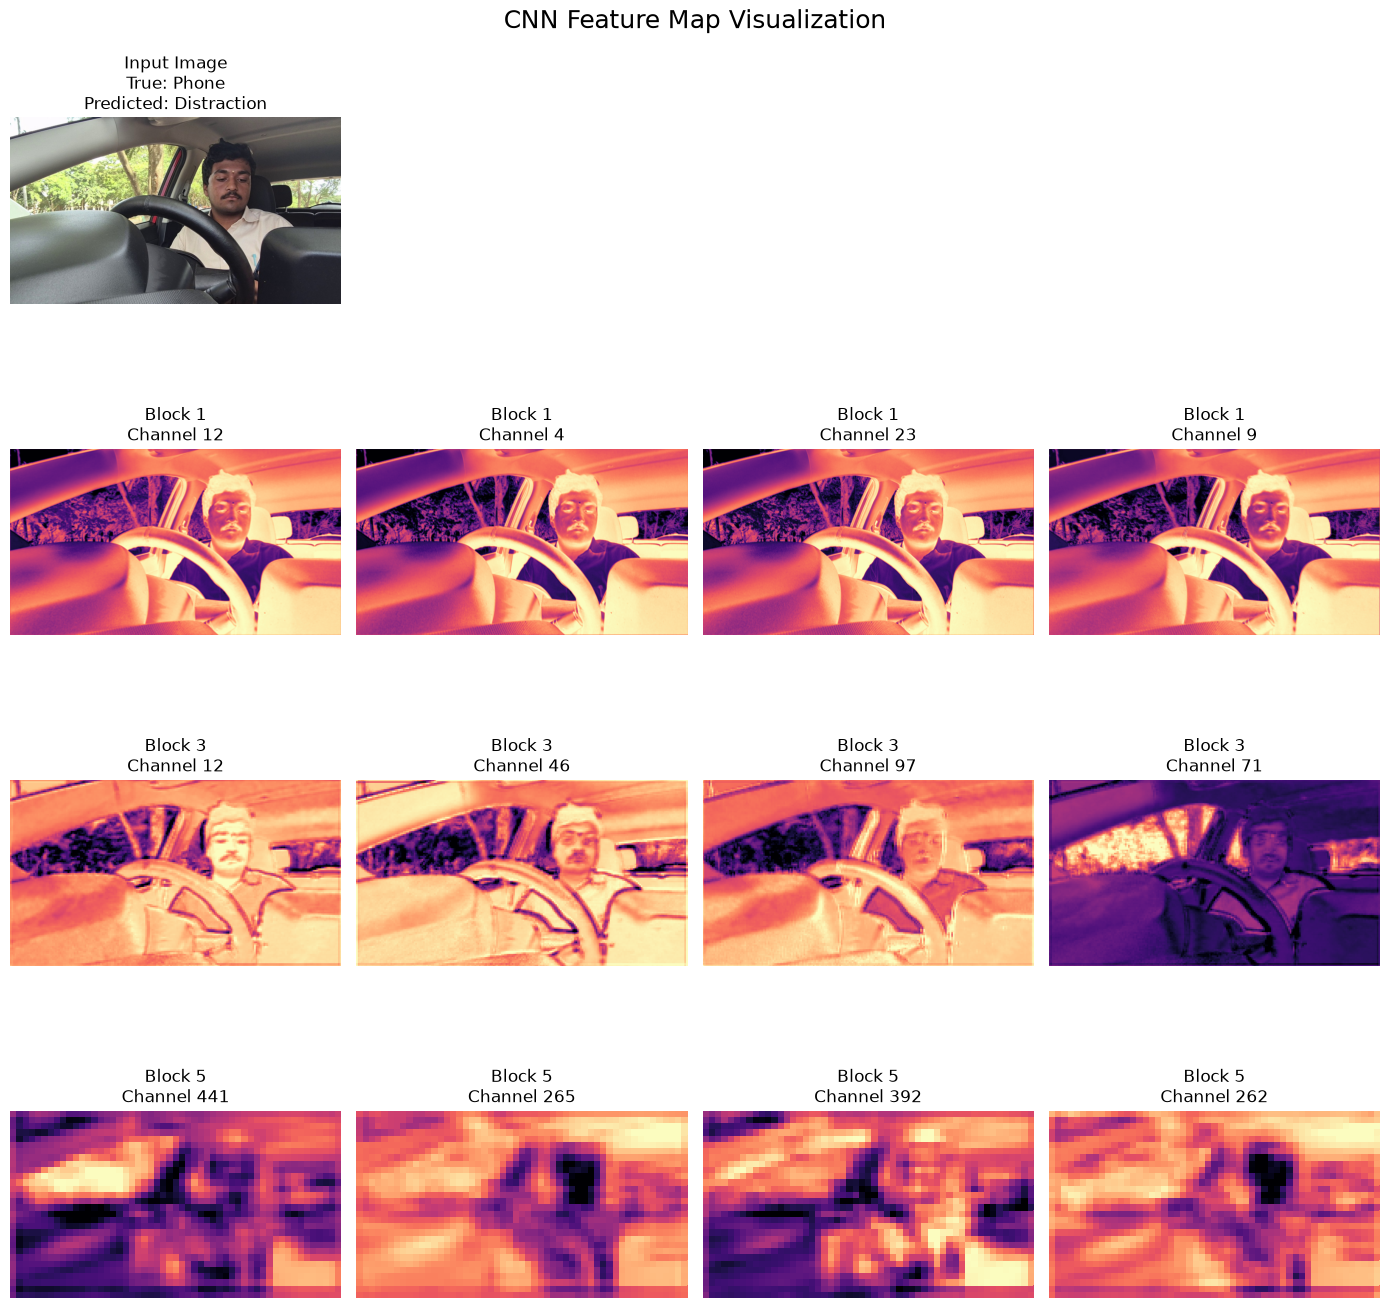

In [30]:
# FEATURE MAP VISUALIZATION
# Using a visually informative test image

import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


# ------------------------------------------------
# LOAD BEST MODEL
# ------------------------------------------------

model.load_state_dict(
    torch.load(
        "best_personwise_custom_cnn.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

model = model.to(DEVICE)
model.eval()


# ------------------------------------------------
# USE SELECTED IMAGE
# ------------------------------------------------

image_path = best_path

original_image = Image.open(
    image_path
).convert("RGB")

true_label = test_df[
    test_df["path"] == image_path
]["class"].iloc[0]

print("Image:", image_path)
print("True Class:", true_label)


# ------------------------------------------------
# MODEL INPUT
# ------------------------------------------------

input_tensor = test_transform(
    original_image
)

input_tensor = input_tensor.unsqueeze(0).to(DEVICE)


# ------------------------------------------------
# FIND CONVOLUTIONAL LAYERS
# ------------------------------------------------

conv_layers = []

for layer in model.features:

    if isinstance(layer, torch.nn.Conv2d):

        conv_layers.append(layer)


print(
    "Convolutional layers:",
    len(conv_layers)
)


# ------------------------------------------------
# CAPTURE ACTIVATIONS
# ------------------------------------------------

activations = {}


def hook_function(name):

    def hook(module, input, output):

        activations[name] = (
            output.detach()
            .cpu()
        )

    return hook


hooks = []


selected_blocks = [1, 3, 5]


for block_number in selected_blocks:

    layer = conv_layers[
        block_number - 1
    ]

    hooks.append(
        layer.register_forward_hook(
            hook_function(
                f"Block {block_number}"
            )
        )
    )


# ------------------------------------------------
# FORWARD PASS
# ------------------------------------------------

with torch.no_grad():

    output = model(
        input_tensor
    )

    prediction = output.argmax(
        dim=1
    ).item()


# Remove hooks

for hook in hooks:

    hook.remove()


print(
    "Predicted Class:",
    CLASSES[prediction]
)


# ------------------------------------------------
# SELECT FEATURE MAPS WITH HIGHEST VARIATION
# ------------------------------------------------

def select_maps(activation, number=4):

    activation = activation[0]

    # Spatial standard deviation
    scores = activation.flatten(
        start_dim=1
    ).std(dim=1)

    indices = torch.argsort(
        scores,
        descending=True
    )[:number]

    return activation[indices], indices


# ------------------------------------------------
# PLOT
# ------------------------------------------------

fig, axes = plt.subplots(
    4,
    4,
    figsize=(14, 14)
)


# INPUT IMAGE

axes[0, 0].imshow(
    original_image
)

axes[0, 0].set_title(
    f"Input Image\n"
    f"True: {true_label}\n"
    f"Predicted: {CLASSES[prediction]}"
)

axes[0, 0].axis("off")


for j in range(1, 4):

    axes[0, j].axis("off")


# BLOCK 1, 3, 5

for row, block_number in zip(
    [1, 2, 3],
    selected_blocks
):

    fmap = activations[
        f"Block {block_number}"
    ]

    selected, indices = select_maps(
        fmap,
        number=4
    )

    for col in range(4):

        feature = selected[
            col
        ].numpy()

        # Percentile contrast enhancement

        low = np.percentile(
            feature,
            1
        )

        high = np.percentile(
            feature,
            99
        )

        feature = np.clip(
            feature,
            low,
            high
        )

        if high > low:

            feature = (
                feature - low
            ) / (
                high - low
            )

        axes[row, col].imshow(
            feature,
            cmap="magma"
        )

        axes[row, col].set_title(
            f"Block {block_number}\n"
            f"Channel {indices[col].item()}"
        )

        axes[row, col].axis("off")


plt.suptitle(
    "CNN Feature Map Visualization",
    fontsize=18
)

plt.tight_layout()

plt.show()